```{index} single: application; fleet assignment
```
```{index} single: solver; HiGHS
```
```{index} pandas dataframe
```
```{index} single: Pyomo; parameters
```
```{index} single: Pyomo; sets
```
```{index} single: Pyomo; expressions
```
```{index} simulations
```
```{index} networkx
```
```{index} Gantt charts
```

# 7.1 Fleet assignment problem

## Problem description

Given a set of flights to be flown, an airline company needs to determine the specific route flown by each airplane in the most cost-effective way. Clearly, the airline company should try to use as few airplanes as possible, but the same airplane can operate two subsequent flights only if the time interval between the arrival of the first flight and the departure of the next flight is longer than or equal to one hour.

Airport compatibility is assumed; only turnaround time restricts connections.

The task of the airline operations team is to determine the minimum number of airplanes needed to operate the given list of flights. This problem is known as the **fleet assignment problem** or **aircraft rotation problem**. We are going to consider the simplest version of the problem where all $M$ available airplanes are assumed to be identical.

## Preamble: Install Pyomo and a solver

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.

In [1]:
import sys
 
if 'google.colab' in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null
 
solver = 'appsi_highs'
 
import pyomo.environ as pyo
SOLVER = pyo.SolverFactory(solver)

assert SOLVER.available(), f"Solver {solver} is not available."

## Generate Flight Data

Times are measured in hours. To reproduce the textbook instance, the call below requests durations of 3, 6, 9 or 12 hours and keeps the defaults of 30 flights, a 24-hour horizon and seed 0. The general generator's default duration range is 1–4 hours; `duration_step` selects the spacing between allowed durations.


In [2]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from numpy.random import RandomState


# python generator creates departure and arrival times for a single airport
def generate_flights(
    N_flights=30, min_duration=1, max_duration=4, max_departure=24, seed=0,
    duration_step=1,
):
    """Yield flights with integer-hour times and durations min + k * step <= max."""
    values = (N_flights, min_duration, max_duration, max_departure, duration_step)
    if not all(isinstance(v, (int, np.integer)) for v in values):
        raise ValueError("Flight counts and time parameters must be integers.")
    if (N_flights < 0 or min_duration <= 0 or max_duration < min_duration
            or duration_step <= 0 or max_departure < min_duration):
        raise ValueError("Use positive durations/step and a horizon that can fit a flight.")
    duration_count = (max_duration - min_duration) // duration_step + 1
    # Retain RandomState and the two uniform draws to reproduce the textbook data.
    rs = RandomState(seed)
    for flight in range(N_flights):
        end_flight = max_departure + 1
        while end_flight > max_departure:
            start_flight = np.floor(max_departure * rs.rand())
            duration = min_duration + duration_step * int(duration_count * rs.rand())
            end_flight = start_flight + duration
        yield flight, int(start_flight), int(end_flight)


# generate flight data
FlightData = pd.DataFrame(
    [[flight, departure, arrival] for flight, departure, arrival in generate_flights(
        min_duration=3, max_duration=12, duration_step=3
    )]
)
FlightData.columns = ["Flight", "Departure", "Arrival"]
FlightData.set_index("Flight", inplace=True)
FlightData

,Departure,Arrival
Flight,,
0,13,22
1,14,23
2,10,19
3,10,22
4,1,4
5,0,12
6,11,23
7,2,11
8,3,15


## Visualize Flight Data

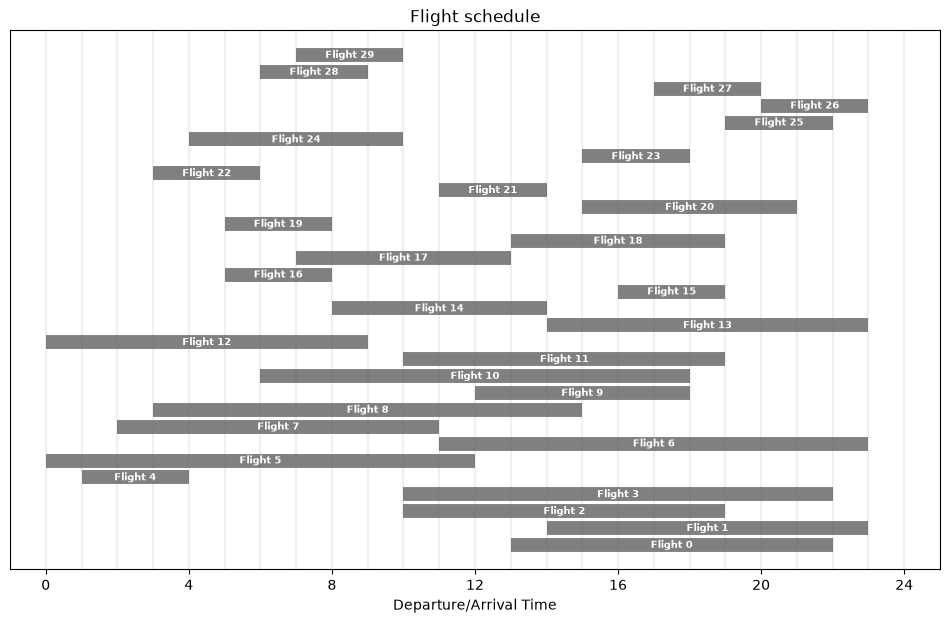

In [3]:
# visualize flight data
def draw_flights(FlightData):
    bar_style = {"alpha": 1.0, "lw": 10, "solid_capstyle": "butt"}
    text_style = {
        "fontsize": 7,
        "color": "white",
        "weight": "bold",
        "ha": "center",
        "va": "center",
    }
    fig = plt.figure(figsize=(12, 7))
    ax = fig.add_subplot(111, xlabel="Departure/Arrival Time", title="Flight schedule")
    ax.get_yaxis().set_visible(False)
    for flight, row in FlightData.iterrows():
        departure, arrival = row
        ax.plot([departure, arrival], [flight] * 2, "gray", **bar_style)
        ax.text((departure + arrival) / 2, flight, f"Flight {flight}", **text_style)
    for hr in range(25):
        ax.axvline(hr, alpha=0.1)
    ax.set_xlim(-1, 25)
    ax.set_xticks([4 * i for i in range(7)])
    return ax


ax = draw_flights(FlightData)

## Pyomo Model

The fleet assignment problem can be formulated and solved as an MILO problem. The idea of the MILO problem formulation is to construct feasible paths in a directed graph where the flights are nodes with indices $\mathcal{F} = \left\{ 1, \ldots, F \right\}$. The set of arcs $\mathcal{A} \subseteq \mathcal{F} \times \mathcal{F}$ that can be used by each aircraft is then:

$$
\mathcal{A} = \{ (f_1, f_2) \ : \ f_1 \text{ arrives at least 1h before the departure of } f_2 \}.
$$

The following cell finds the set of arcs that can be used. These arcs are displayed in a graph of the flight data. Arcs corresponding to the minimum time between arrival and departure are highlighted in red.

The mathematical formulation uses flight indices $1,\ldots,F$; the DataFrame uses labels $0,\ldots,F-1$. The dummy nodes in the next illustrative formulation are separate from those DataFrame labels.


In [4]:
min_time = 1


def feasible_flight_pairs(FlightData, min_time=1):
    # return a dictionary of turnaround times indexed by flight pairs
    turnaround = (
        lambda pair: FlightData.loc[pair[1], "Departure"]
        - FlightData.loc[pair[0], "Arrival"]
    )
    pairs = filter(
        lambda pair: turnaround(pair) >= min_time,
        [(i, j) for i in FlightData.index for j in FlightData.index if i != j],
    )
    return {pair: turnaround(pair) for pair in pairs}


flight_pairs = feasible_flight_pairs(FlightData).keys()

The following cell presents a visualization of the graph of feasible paths in which an aircraft can be reassigned from one flight to subsequent flight. Each node on the graph corresponds to a flight. An edge from flight $f_1$ to flight $f_2$ is included only if there is at least `min_time` hours available to `turn around` the aircraft. Edges that allow exactly `min_time` hours between flights are colored red because these leave no slack beyond the assumed minimum turnaround.

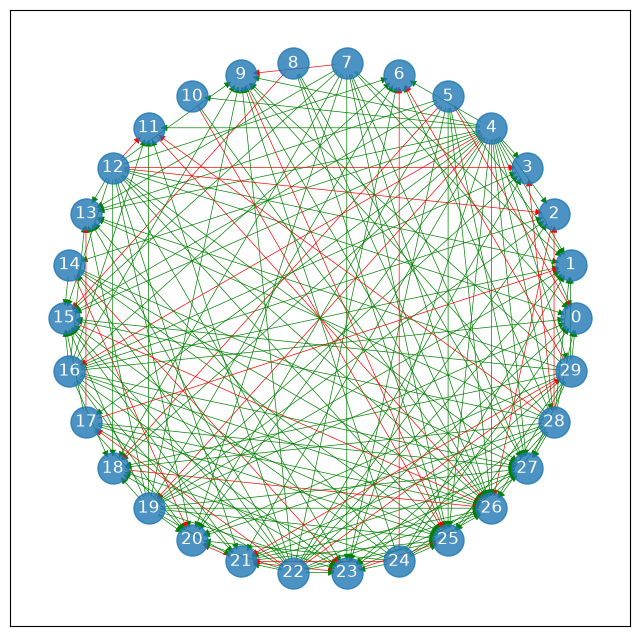

In [5]:
dg = nx.DiGraph()

for flight in FlightData.index:
    _ = dg.add_node(flight)

for pair, dur in feasible_flight_pairs(FlightData, min_time).items():
    _ = dg.add_edge(pair[0], pair[1], color="r" if dur <= min_time else "g")

size = int(1.5 * np.sqrt(len(FlightData)))
fig = plt.figure(figsize=(size, size))
pos = nx.circular_layout(dg)
nx.draw_networkx_nodes(dg, pos=pos, node_size=500, alpha=0.8)
nx.draw_networkx_labels(dg, pos=pos, font_color="w")
nx.draw_networkx_edges(
    dg, pos=pos, width=0.5, edge_color=[dg.edges[u, v]["color"] for u, v in dg.edges]
)
plt.show()

### Naive model formulation

An idea of an MILO formulation of the problem is to construct a feasible path for each aircraft in a graph where the flights are nodes with indices $1, \ldots, F$, and there is one source node $0$ and a sink node $F + 1$. The set of arcs $\mathcal{A}'$ that can be used by each aircraft is then:

$$
\mathcal{A'} = 
\bigcup_{f_1,f_2 \in \mathcal{F}} \{ (f_1, f_2) ~:~ f_1 \text{ arrives at least 1h before departure of } f_2 \} \cup \bigcup_{f \in \mathcal{F}}  \{ (0, f), \ (f, F+1)\}
$$

where $0$ and $F + 1$ play the role of dummy flights before the first/after the last flight of a given aircraft's assignment.

Denote the set of aircraft indices as $\mathcal{M} = \{ 1, \ldots, M\}$. The decision variables then are:
- $x_{f_1, f_2, i} \in \{0, 1\}$, $(f_1, f_2) \in \mathcal{A}'$, $i \in \mathcal{M}$ indicating whether the connection $(f_1, f_2)$ is operated by aircraft $i$
- $y_i \in \{0, 1\}$, for $i \in \mathcal{M}$ indicating whether aircraft $i$ is used or not

The corresponding MILO problem is then:

$$
\begin{align}
    \min \quad & \sum\limits_{i \in \mathcal{M}} y_i \tag{a}\\
    \text{s.t.} \quad 
    & \sum\limits_{f_1:(f_1,f)\in\mathcal{A}'} x_{f_1, f, i} = \sum\limits_{f_2:(f,f_2)\in\mathcal{A}'} x_{f, f_2, i} & \forall \, f \in \mathcal{F}, \ \forall \, i \in \mathcal{M} \tag{b}\\
    & \sum\limits_{i \in \mathcal{M}} \sum\limits_{f':(f',f)\in\mathcal{A}'} x_{f', f, i} = 1 & \forall \, f \in \mathcal{F} \tag{c}\\
    & \sum\limits_{(0, f) \in \mathcal{A}'} x_{0, f, i} \leq 1 & \forall \, i \in \mathcal{M} \tag{d}\\
    & x_{0, f, i} \leq y_i & \forall \, f \in \mathcal{F}, \ \forall \, i \in \mathcal{M} \tag{e}\\
    & x_{f_1,f_2,i} \in \{0,1\} & \forall \, (f_1,f_2) \in \mathcal{A}',\ i \in \mathcal{M} \tag{f}\\
    & y_i \in \{0,1\} & \forall \, i \in \mathcal{M} \tag{g}
\end{align}
$$

where
- the objective function (a) aims to minimize the number of airplanes used;
- constraint (b) enforces that for a given real flight the number of used incoming arcs with airplane $i$ must be equal to the number of outgoing arcs with this airplane;
- constraint (c) ensures that each flight is operated by exactly one aircraft;
- constraint (d) enforces that each airplane serves at most one sequence of flights;
- constraint (e) ensures that if at least one arc $(0, f)$ is used by a given airplane, then this airplane is used;
- constraints (f) and (g) are the integrality constraints.

This formulation is very explicit and each decision there clearly corresponds to a real-life decision. However, it has a drawback -- it is blind to the aircraft being all identical. Consider a situation where aircraft $1$ is assigned to operate flights $(1, 2, 3)$ and aircraft $2$ is assigned to operate flights $(4, 5)$. Then, one can simply swap the flight assignment of the two aircraft between them and arrive at another solution that is essentially the same if the aircraft are all identical. In terms of mathematical optimization, this means that the problem has a lot of *symmetry* which produces a huge solution space that the solving algorithm has to explore. 

A normal practice is to eliminate symmetry from the problem, for example, by adding so-called *symmetry-breaking constraints* that do not change the problem but allow only one out of many equivalent solutions. Here, one such constraint would be

$$
\begin{align*}
y_i \leq y_{i - 1} & \qquad \forall \, i \in \mathcal{M}: \ i > 1,
\end{align*}
$$

which would ensure, at least, that we utilize airplanes in the order they appear on the list, i.e., aircraft $2$ cannot be used if aircraft $1$ was not used. However, an even better way of removing symmetry from the problem is to remove the airplanes from the model altogether.

### Symmetry-free and totally-unimodular model formulation

In the next model we only create flight combinations to be operated by a single aircraft and assign the actual aircraft in a post-processing step. First, for each node $f\in\mathcal{F}$ in the DiGraph we define a set of input nodes $\mathcal{I}_f = \{f_1: (f_1, f)\in\mathcal{A}\}$  and a set of output nodes $\mathcal{O}_f = \{f_1: (f, f_1)\in\mathcal{A} \}$. For this application, we use the Python ``set`` object to scan the feasible flight pairs and find the input and output nodes for each flight node. 

In [6]:
in_nodes = {flight: set() for flight in FlightData.index}
out_nodes = {flight: set() for flight in FlightData.index}

for flight1, flight2 in flight_pairs:
    in_nodes[flight2].add(flight1)
    out_nodes[flight1].add(flight2)

The decision variables are:

* $x_{f_1, f_2}\in\{0,1\}$ for all $(f_1, f_2) \in\mathcal{A}$ where $x_{f_1, f_2} = 1$ indicates that an aircraft used for arriving flight $f_1$ will be used for departing flight $f_2$.

* $p_f\in\{0,1\}$ for all $f\in\mathcal{F}$ where $p_f = 1$ indicates a previously unassigned aircraft will be used for departing flight $f$.

* $q_f\in\{0,1\}$ for all $f\in\mathcal{F}$ where $q_f = 1$ indicates an aircraft will be unassigned after arrival of flight $f$.

The binary variables $p_f$ and $q_f$ correspond to arcs that link nodes to the sources and sinks of aircraft needed to complete all of the flights $f\in\mathcal{F}$. The objective is to minimize the number of required aircraft subject to the constraints that exactly one aircraft is assigned to and released from each node.

$$
\begin{align}
\min \quad & \sum_{f\in\mathcal{F}} p_f \\
\text{s.t.}\quad & p_f + \sum_{f_1\in\mathcal{I}_f} x_{f_1, f} = 1 & \forall f\in\mathcal{F} \\
& q_f + \sum_{f_1\in\mathcal{O}_f} x_{f, f_1} = 1 & \forall f\in\mathcal{F} \\
& x_{f_1,f_2}\in\{0,1\} & \forall (f_1,f_2)\in\mathcal{A} \\
& p_f,q_f\in\{0,1\} & \forall f\in\mathcal{F}
\end{align}
$$

Positive flight durations and forward-time connections make this graph acyclic, so the balance constraints produce paths rather than cycles.

This model will give solutions where decisions $x_{f_1, f_2}$ will yield paths corresponding to sequences of flights that can be operated with a single aircraft. To such paths, we can assign aircraft in an arbitrary fashion after the optimization is finished.

The constraint matrix is **totally unimodular**: each connection column joins the incoming balance of one flight to the outgoing balance of another, giving the incidence matrix of a bipartite graph; the $p$ and $q$ columns have a single nonzero entry. With integer right-hand sides and bounds, the continuous relaxation has integer extreme points. Thus an integral optimal solution can be found without binary domains; this does not mean every feasible continuous solution is integral.

The next cell solves the binary model and then demonstrates its continuous relaxation with bounds $[0,1]$ on a separate clone. We compare their optima and check termination and integrality. The integrality check on the relaxation relies on a basic (vertex) LP solution, as HiGHS returns here; an interior-point method without crossover can instead return a fractional optimal solution. The following diagrams and schedules use the original binary solve; the later fleet-limit/risk examples also retain binary domains.


In [7]:
m = pyo.ConcreteModel("Fleet Assignment")

m.FLIGHTS = pyo.Set(initialize=FlightData.index)
m.PAIRS = pyo.Set(initialize=list(flight_pairs))

m.x = pyo.Var(m.PAIRS, domain=pyo.Binary)
m.p = pyo.Var(m.FLIGHTS, domain=pyo.Binary)
m.q = pyo.Var(m.FLIGHTS, domain=pyo.Binary)


@m.Constraint(m.FLIGHTS)
def sources(m, flight):
    return m.p[flight] + sum(m.x[_, flight] for _ in in_nodes[flight]) == 1


@m.Constraint(m.FLIGHTS)
def sinks(m, flight):
    return m.q[flight] + sum(m.x[flight, _] for _ in out_nodes[flight]) == 1


@m.Objective(sense=pyo.minimize)
def minimize_airplanes(m):
    return pyo.summation(m.p)


results = SOLVER.solve(m)
pyo.assert_optimal_termination(results)
assert all(abs(pyo.value(v) - round(pyo.value(v))) <= 1e-6
           for v in m.component_data_objects(pyo.Var)), "Expected an integral solution."

# Demonstrate the LO relaxation without replacing the illustrative binary schedule.
relaxed = m.clone()
for variable in relaxed.component_data_objects(pyo.Var):
    variable.domain = pyo.UnitInterval
relaxed_results = SOLVER.solve(relaxed)
pyo.assert_optimal_termination(relaxed_results)
assert abs(pyo.value(relaxed.minimize_airplanes) - pyo.value(m.minimize_airplanes)) <= 1e-6
assert all(abs(pyo.value(v) - round(pyo.value(v))) <= 1e-6
           for v in relaxed.component_data_objects(pyo.Var)), "Expected an integral LO solution."

print(f"Minimum airplanes required = {m.minimize_airplanes()}")
print(f"Continuous relaxation also requires {pyo.value(relaxed.minimize_airplanes):.0f} airplanes")

Minimum airplanes required = 14.0
Continuous relaxation also requires 14 airplanes


We visualize the solution by redrawing the graph of possible paths and highlighting the edges that have been selected for aircraft reassignment. 

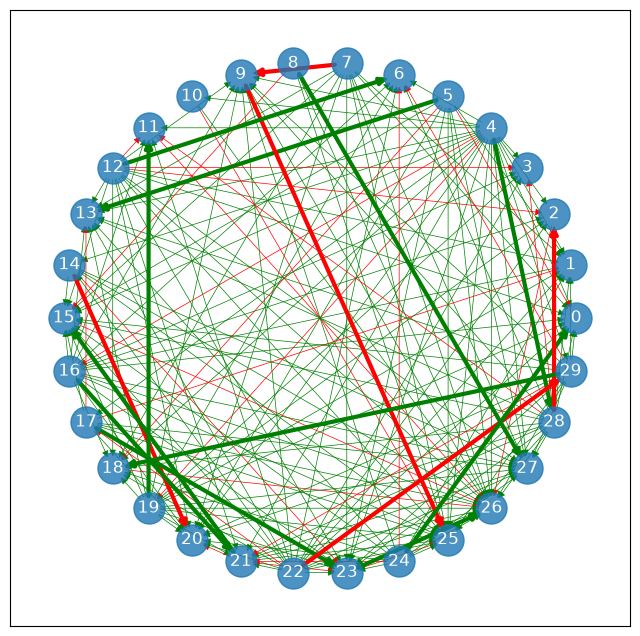

In [8]:
dg_soln = nx.DiGraph()

for flight in FlightData.index:
    dg_soln.add_node(flight)

for pair, dur in feasible_flight_pairs(FlightData, min_time).items():
    if m.x[pair[0], pair[1]].value > 0.5:
        dg_soln.add_edge(pair[0], pair[1], color="r" if dur <= min_time else "g")

size = int(1.5 * np.sqrt(len(FlightData)))
fig = plt.figure(figsize=(size, size))

nx.draw_networkx_nodes(dg_soln, pos=pos, node_size=500, alpha=0.8)
nx.draw_networkx_labels(dg_soln, pos=pos, font_color="w")
nx.draw_networkx_edges(
    dg, pos=pos, width=0.5, edge_color=[dg.edges[u, v]["color"] for u, v in dg.edges]
)
nx.draw_networkx_edges(
    dg_soln,
    pos=pos,
    width=3,
    edge_color=[dg_soln.edges[u, v]["color"] for u, v in dg_soln.edges],
)
plt.show()

We visualize the solution by drawing arcs where $x_{f_1, f_2} = 1$ and where $p_f = 1$ and $q_f = 1$. These arcs draw feasible paths through the graph corresponding to the assignment of one aircraft to service one or more flights. The arcs are green if the time between the two flights is strictly larger than the minimum layover time (1h) and red if it is equal.

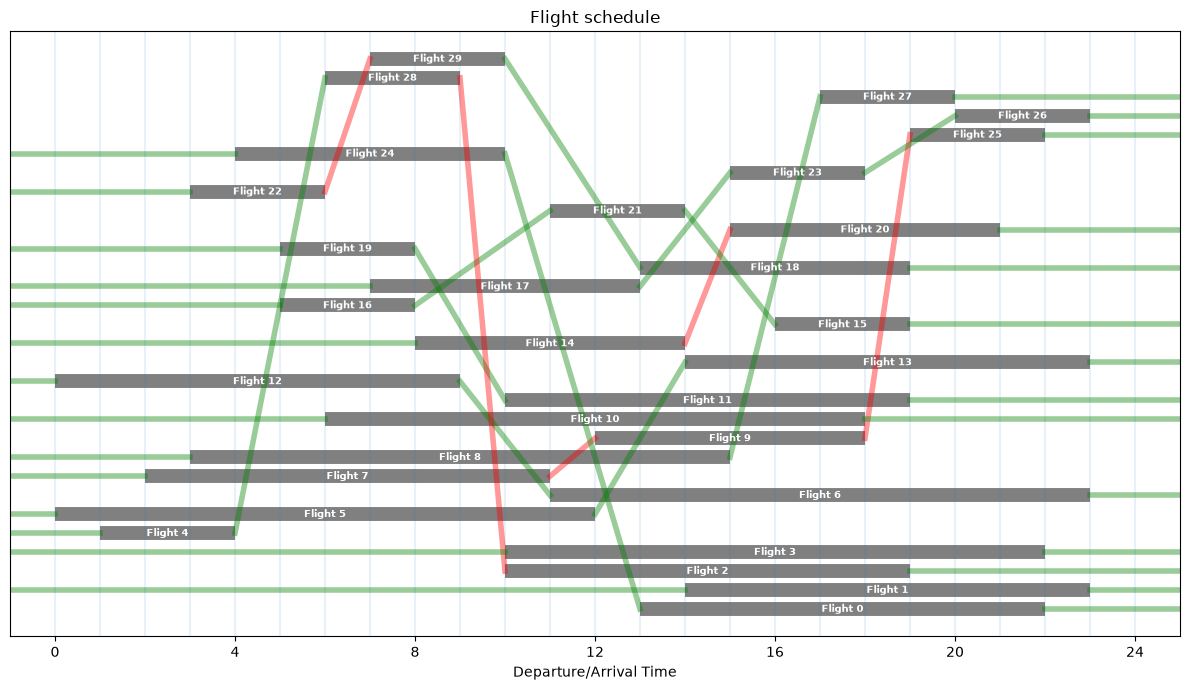

In [9]:
ax = draw_flights(FlightData)
for flight1, flight2 in flight_pairs:
    if m.x[flight1, flight2]() > 0.5:
        arr = FlightData.loc[flight1, "Arrival"]
        dep = FlightData.loc[flight2, "Departure"]
        c = "r" if dep - arr <= min_time else "g"
        ax.plot([arr, dep], [flight1, flight2], color=c, lw=4, alpha=0.4)

for flight in FlightData.index:
    if m.p[flight]() > 0.5:
        dep = FlightData.loc[flight, "Departure"]
        ax.plot([-1, dep], [flight] * 2, "g", lw=4, alpha=0.4)
    if m.q[flight]() > 0.5:
        arr = FlightData.loc[flight, "Arrival"]
        ax.plot([arr, 25], [flight] * 2, "g", lw=4, alpha=0.4)

plt.tight_layout()
plt.show()

## Create Flight and Aircraft Schedules

* **Flight Schedule**: A table indexed by flight numbers showing the assigned aircraft, departure, and arrival times.
* **Aircraft Schedule**: A table indexed by aircraft and flights showing departure and arrival times. 

In [10]:
FlightSchedule = FlightData.copy()

# create a generator of aircraft ids
aircraft = (f"A{n+1:02d}" for n in range(len(FlightData.index)))

# traverse each path through the graph
for f in FlightData.index:
    if m.p[f]() > 0.5:
        aircraft_id = next(aircraft)
        FlightSchedule.loc[f, "Aircraft"] = aircraft_id
        while m.q[f]() < 0.5:
            f = next(filter(lambda _: m.x[f, _]() > 0.5, out_nodes[f]))
            FlightSchedule.loc[f, "Aircraft"] = aircraft_id

FlightSchedule = FlightSchedule[["Aircraft", "Departure", "Arrival"]]
display(FlightSchedule)

,Aircraft,Departure,Arrival
Flight,,,
0,A14,13,22
1,A01,14,23
2,A03,10,19
3,A02,10,22
4,A03,1,4
5,A04,0,12
6,A08,11,23
7,A05,2,11
8,A06,3,15


In [11]:
AircraftSchedule = FlightSchedule.copy()
AircraftSchedule["Flight"] = AircraftSchedule.index
AircraftSchedule = AircraftSchedule.sort_values(["Aircraft", "Departure"])
AircraftSchedule.index = pd.MultiIndex.from_frame(
    AircraftSchedule[["Aircraft", "Flight"]]
)
AircraftSchedule = AircraftSchedule[["Departure", "Arrival"]]
display(AircraftSchedule)

Departure  Arrival
Aircraft Flight                    
A01      1              14       23
A02      3              10       22
A03      4               1        4
         28              6        9
         2              10       19
A04      5               0       12
         13             14       23
A05      7               2       11
         9              12       18
         25             19       22
A06      8               3       15
         27             17       20
A07      10              6       18
A08      12              0        9
         6              11       23
A09      14              8       14
         20             15       21
A10      16              5        8
         21             11       14
         15             16       19
A11      17              7       13
         23             15       18
         26             20       23
A12      19              5        8
         11             10       19
A13      22              3        6
         29              7       10
         18             13       19
A14      24              4       10
         0              13       22

## Reducing riskiness of the schedule

We now keep all 30 flights and bound the number of aircraft by `N_planes`, while minimizing the number of tight connections. A connection is counted when its turnaround is exactly the chosen minimum `min_time`. This is a scheduling proxy for vulnerability to delays, not a delay probability.

The model uses the same incoming/outgoing balances, binary variables and the additional fleet limit

$$
\sum_{f\in\mathcal F}p_f\leq N_{\mathrm{planes}}.
$$

Its objective is $\min\sum_{(f,g)\in\mathcal A}c_{fg}x_{fg}$, where $c_{fg}=1$ if the turnaround equals `min_time`, and $c_{fg}=0$ otherwise. The feasible arc set is rebuilt for that minimum. The aircraft count is an upper bound, rather than an instruction to use unnecessary aircraft.

The initial 14-aircraft schedule above has five tight one-hour connections. The first case uses the same minimum fleet of 14 aircraft and a one-hour minimum, reducing that count to two. The second allows 15 aircraft with the same one-hour minimum, showing the benefit of an extra aircraft. The third keeps the 15-aircraft limit and requires two hours between flights; its red arcs count two-hour connections. Counts for the one-hour and two-hour cases therefore refer to different tightness thresholds. A maximum matching has 15 connections at this threshold, so 15 aircraft is also the minimum fleet for the two-hour turnaround: this case has no spare aircraft. Each solve prints its aircraft use and tight-connection count alongside the plot.


In [12]:
def schedule(FlightData, N_planes, min_time=1):
    pairs = feasible_flight_pairs(FlightData, min_time)

    weights = {pair: int(pairs[pair] == min_time) for pair in pairs}

    in_nodes = {flight: set() for flight in FlightData.index}
    out_nodes = {flight: set() for flight in FlightData.index}

    for flight1, flight2 in pairs.keys():
        in_nodes[flight2].add(flight1)
        out_nodes[flight1].add(flight2)

    m = pyo.ConcreteModel("Fleet Assignment - Minimize Risk")

    m.FLIGHTS = pyo.Set(initialize=FlightData.index)
    m.PAIRS = pyo.Set(initialize=pairs.keys())

    m.x = pyo.Var(m.PAIRS, domain=pyo.Binary)
    m.p = pyo.Var(m.FLIGHTS, domain=pyo.Binary)
    m.q = pyo.Var(m.FLIGHTS, domain=pyo.Binary)

    @m.Constraint(m.FLIGHTS)
    def sources(m, flight):
        return m.p[flight] + sum(m.x[_, flight] for _ in in_nodes[flight]) == 1

    @m.Constraint(m.FLIGHTS)
    def sinks(m, flight):
        return m.q[flight] + sum(m.x[flight, _] for _ in out_nodes[flight]) == 1

    @m.Constraint()
    def fleet_limit(m):
        return pyo.summation(m.p) <= N_planes

    @m.Objective(sense=pyo.minimize)
    def minimize_risk(m):
        return sum(m.x[pair] * weights[pair] for pair in m.PAIRS)

    return m

Aircraft used: 14 (limit 14)
Connections at the 1-hour minimum: 2


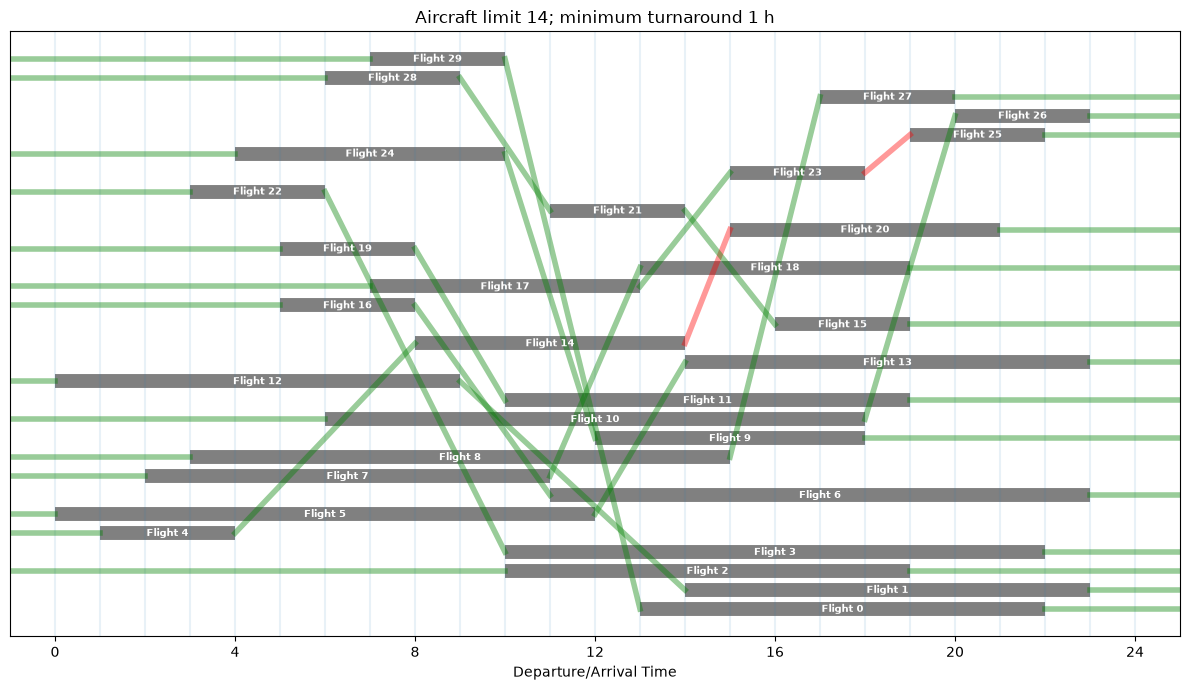

In [13]:
min_time = 1
N_planes = 14

m = schedule(FlightData, N_planes, min_time)
results = SOLVER.solve(m)
pyo.assert_optimal_termination(results)
assert all(abs(pyo.value(v) - round(pyo.value(v))) <= 1e-6
           for v in m.component_data_objects(pyo.Var)), "Expected binary decisions."
used_planes = sum(m.p[f]() > 0.5 for f in m.FLIGHTS)
print(f"Aircraft used: {used_planes} (limit {N_planes})")
print(f"Connections at the {min_time}-hour minimum: {pyo.value(m.minimize_risk):.0f}")

pairs = feasible_flight_pairs(FlightData, min_time)
ax = draw_flights(FlightData)
ax.set_title(f"Aircraft limit {N_planes}; minimum turnaround {min_time} h")
for flight1, flight2 in pairs.keys():
    if m.x[flight1, flight2]() > 0.5:
        arr = FlightData.loc[flight1, "Arrival"]
        dep = FlightData.loc[flight2, "Departure"]
        c = "r" if dep - arr <= min_time else "g"
        ax.plot([arr, dep], [flight1, flight2], color=c, lw=4, alpha=0.4)

for flight in FlightData.index:
    if m.p[flight]() > 0.5:
        dep = FlightData.loc[flight, "Departure"]
        ax.plot([-1, dep], [flight] * 2, "g", lw=4, alpha=0.4)
    if m.q[flight]() > 0.5:
        arr = FlightData.loc[flight, "Arrival"]
        ax.plot([arr, 25], [flight] * 2, "g", lw=4, alpha=0.4)
plt.tight_layout()
plt.show()

Aircraft used: 15 (limit 15)
Connections at the 1-hour minimum: 0


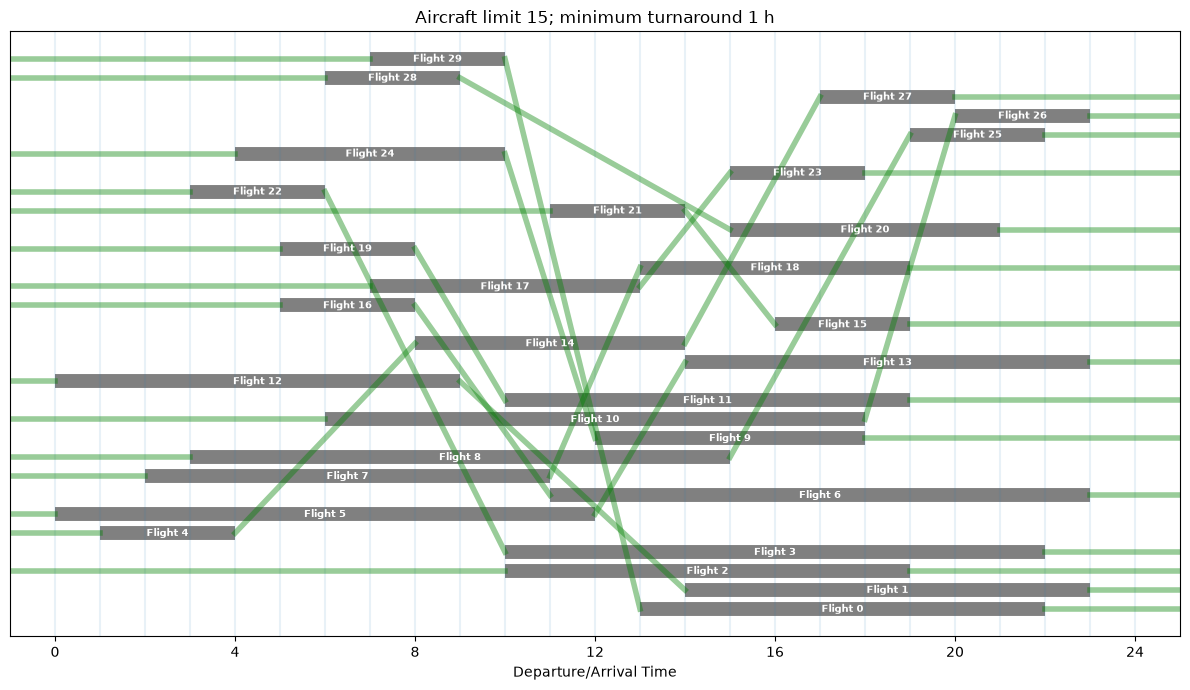

In [14]:
min_time = 1
N_planes = 15

m = schedule(FlightData, N_planes, min_time)
results = SOLVER.solve(m)
pyo.assert_optimal_termination(results)
assert all(abs(pyo.value(v) - round(pyo.value(v))) <= 1e-6
           for v in m.component_data_objects(pyo.Var)), "Expected binary decisions."
used_planes = sum(m.p[f]() > 0.5 for f in m.FLIGHTS)
print(f"Aircraft used: {used_planes} (limit {N_planes})")
print(f"Connections at the {min_time}-hour minimum: {pyo.value(m.minimize_risk):.0f}")

pairs = feasible_flight_pairs(FlightData, min_time)
ax = draw_flights(FlightData)
ax.set_title(f"Aircraft limit {N_planes}; minimum turnaround {min_time} h")
for flight1, flight2 in pairs.keys():
    if m.x[flight1, flight2]() > 0.5:
        arr = FlightData.loc[flight1, "Arrival"]
        dep = FlightData.loc[flight2, "Departure"]
        c = "r" if dep - arr <= min_time else "g"
        ax.plot([arr, dep], [flight1, flight2], color=c, lw=4, alpha=0.4)

for flight in FlightData.index:
    if m.p[flight]() > 0.5:
        dep = FlightData.loc[flight, "Departure"]
        ax.plot([-1, dep], [flight] * 2, "g", lw=4, alpha=0.4)
    if m.q[flight]() > 0.5:
        arr = FlightData.loc[flight, "Arrival"]
        ax.plot([arr, 25], [flight] * 2, "g", lw=4, alpha=0.4)
plt.tight_layout()
plt.show()

Aircraft used: 15 (limit 15)
Connections at the 2-hour minimum: 3


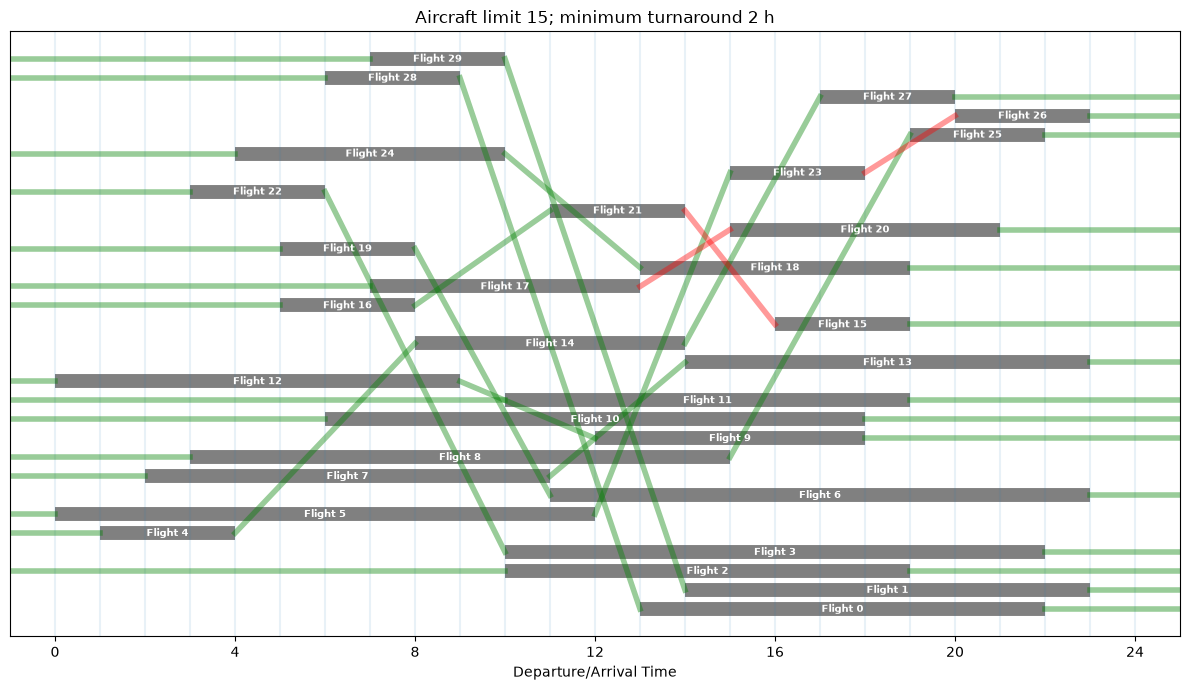

In [15]:
min_time = 2
N_planes = 15

m = schedule(FlightData, N_planes, min_time)
results = SOLVER.solve(m)
pyo.assert_optimal_termination(results)
assert all(abs(pyo.value(v) - round(pyo.value(v))) <= 1e-6
           for v in m.component_data_objects(pyo.Var)), "Expected binary decisions."
used_planes = sum(m.p[f]() > 0.5 for f in m.FLIGHTS)
print(f"Aircraft used: {used_planes} (limit {N_planes})")
print(f"Connections at the {min_time}-hour minimum: {pyo.value(m.minimize_risk):.0f}")

pairs = feasible_flight_pairs(FlightData, min_time)
ax = draw_flights(FlightData)
ax.set_title(f"Aircraft limit {N_planes}; minimum turnaround {min_time} h")
for flight1, flight2 in pairs.keys():
    if m.x[flight1, flight2]() > 0.5:
        arr = FlightData.loc[flight1, "Arrival"]
        dep = FlightData.loc[flight2, "Departure"]
        c = "r" if dep - arr <= min_time else "g"
        ax.plot([arr, dep], [flight1, flight2], color=c, lw=4, alpha=0.4)

for flight in FlightData.index:
    if m.p[flight]() > 0.5:
        dep = FlightData.loc[flight, "Departure"]
        ax.plot([-1, dep], [flight] * 2, "g", lw=4, alpha=0.4)
    if m.q[flight]() > 0.5:
        arr = FlightData.loc[flight, "Arrival"]
        ax.plot([arr, 25], [flight] * 2, "g", lw=4, alpha=0.4)
plt.tight_layout()
plt.show()